In [13]:
# VERİ SETİ GENEL ÖZELLİKLERİ 
import os
from PIL import Image

veri_setleri = {
    "Veri 1 (Klasör Sınıflandırmalı)": "../data/veri_seti_1",
    "Veri 2 (Ayrı Klasör Etiketli)": "../data/veri_seti_2",
    "Veri 3 (YOLOv8 Formatı)": "../data/veri_seti_3"
}

print("BÖLÜM 2.2: TÜM İSTERLERİ KAPSAYAN NİHAİ ANALİZ")
print("=" * 65)

for isim, yol in veri_setleri.items():
    if not os.path.exists(yol):
        continue

    # Tüm metrikler için sayaçlar
    toplam_gorsel = 0
    kus_sayisi = 0
    drone_sayisi = 0
    etiket_sayisi = 0
    egitim_sayisi = 0
    dogrulama_sayisi = 0
    test_sayisi = 0
    bozuk_gorsel = 0
    
    genislikler = set()
    yukseklikler = set()
    formatlar = set()

    for root, dirs, files in os.walk(yol):
        root_lower = root.lower()
        
        for file in files:
            dosya_uzantisi = file.lower()
            dosya_yolu = os.path.join(root, file)
            
            # 1. Görselleri Sayma, Sınıflandırma ve Boyut/Bozuk Kontrolü
            if dosya_uzantisi.endswith(('.png', '.jpg', '.jpeg')):
                toplam_gorsel += 1
                formatlar.add(dosya_uzantisi.replace('.', ''))
                
                # Sınıfları ve Dağılımları Tespit Etme
                if 'bird' in root_lower:
                    kus_sayisi += 1
                elif 'drone' in root_lower:
                    drone_sayisi += 1
                    
                if 'train' in root_lower:
                    egitim_sayisi += 1
                elif 'val' in root_lower or 'valid' in root_lower:
                    dogrulama_sayisi += 1
                elif 'test' in root_lower:
                    test_sayisi += 1
                    
                # Boyut ve Bozuk Veri Kontrolü (Geri eklendi)
                try:
                    with Image.open(dosya_yolu) as img:
                        img.verify() # Resim bozuk mu?
                    with Image.open(dosya_yolu) as img:
                        if len(genislikler) < 2: # Rapora koymak için 2 örnek boyut yeterli
                            genislikler.add(img.width)
                            yukseklikler.add(img.height)
                except Exception:
                    bozuk_gorsel += 1
                    
            # 2. Etiket Dosyalarını Sayma
            elif dosya_uzantisi.endswith('.txt') and 'classes' not in dosya_uzantisi and 'readme' not in dosya_uzantisi:
                etiket_sayisi += 1

    # Rapor Formatında Çıktı
    print(f"--- {isim} ---")
    print(f"Toplam Veri Sayısı: {toplam_gorsel}")
    print(f"Veri Formatı: {', '.join(formatlar)}")
    print(f"Veri Boyutu Özellikleri (Örnek Çözünürlükler): {', '.join([f'{g}x{y}' for g, y in zip(genislikler, yukseklikler)])}")
    
    if egitim_sayisi > 0 or dogrulama_sayisi > 0 or test_sayisi > 0:
        print(f"Dağılım: Eğitim: {egitim_sayisi} | Doğrulama: {dogrulama_sayisi} | Test: {test_sayisi}")
    else:
        print("Dağılım: Tek klasör (Eğitim/Test ayrımı yapılmamış)")
        
    print(f"Sınıf Sayısı: 2")
    print(f"Sınıflara Göre Veri Dağılımı: Kuş (Bird): {kus_sayisi} | İHA (Drone): {drone_sayisi}")
    
    print(f"Eksik/Bozuk Veri Durumu: {bozuk_gorsel} adet bozuk görsel tespit edildi.")
    if etiket_sayisi == 0:
        print("Etiket Durumu: Etiket (.txt) dosyası yok (Sınıflandırma klasör isimleriyle yapılmış)")
    else:
        print(f"Etiket Durumu: {etiket_sayisi} adet etiket dosyası mevcut")
    print("=" * 65)

BÖLÜM 2.2: TÜM İSTERLERİ KAPSAYAN NİHAİ ANALİZ
--- Veri 1 (Klasör Sınıflandırmalı) ---
Toplam Veri Sayısı: 4104
Veri Formatı: 000000000404jpg, singlebirdinsky25_r90jpg, singlebirdinsky111_r180_darkerjpg, 000000000592jpg, singlebirdinsky54_r90jpg, singlebirdinsky264_r180jpg, singlebirdinsky28_r90jpg, 157jpg, 000000000555jpg, 101006jpg, singlebirdinsky206_r180jpg, 176jpeg, 000000000116jpg, singledronesinsky238jpeg, singlebirdinsky74_r90jpg, 100063jpg, singlebirdinsky301_r180jpg, 100617jpg, 100287jpg, 100183jpg, singlebirdinsky215jpg, singlebirdinsky260jpg, 101329jpg, singlebirdinsky395_r180jpg, 100426jpg, img_plane3_37jpg, 000000000704jpg, singlebirdinsky10_darkerjpg, 000000000862jpg, 000000000721jpg, 000000000194jpg, 97jpeg, singlebirdinsky43jpeg, singlebirdinsky105jpeg, 123jpeg, 100594jpg, singlebirdinsky156_r180jpg, singlebirdinsky106_r90_blurjpg, 112jpeg, 000000000775jpg, singledronesinsky85jpeg, singlebirdinsky1_r90jpg, 000000000137jpg, singlebirdinsky218jpg, singlebirdinsky240_r90j

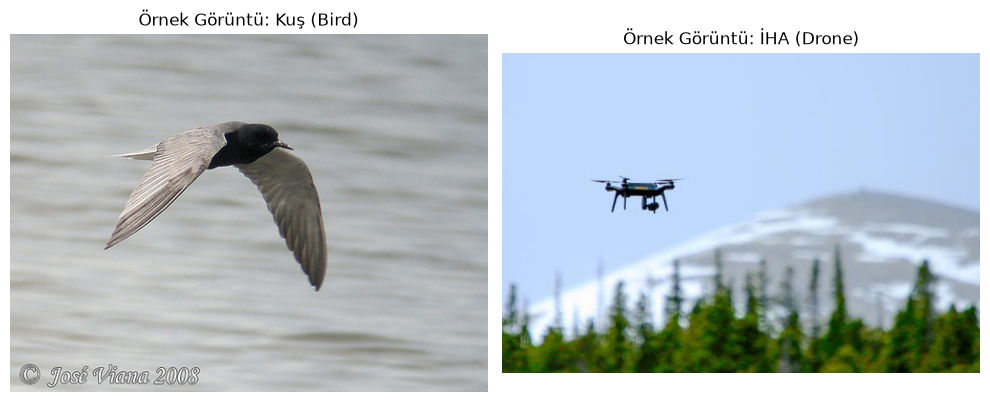

In [17]:
# VERİ SETİNDEN ÖRNEKLER  

import matplotlib.pyplot as plt
from PIL import Image
import os

kus_resmi = None
drone_resmi = None

# Veri klasörlerinde gezip ilk bulduğumuz kuş ve drone resimlerini alıyoruz
for root, dirs, files in os.walk("../data"):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            if 'bird' in root.lower() and not kus_resmi:
                kus_resmi = os.path.join(root, file)
            elif 'drone' in root.lower() and not drone_resmi:
                drone_resmi = os.path.join(root, file)
        
        if kus_resmi and drone_resmi:
            break

# Çizim Ekranını Ayarlama
plt.figure(figsize=(10, 5))

# Sol tarafa Kuş resmini koy
plt.subplot(1, 2, 1)
plt.imshow(Image.open(kus_resmi))
plt.title("Örnek Görüntü: Kuş (Bird)")
plt.axis('off')

# Sağ tarafa İHA resmini koy
plt.subplot(1, 2, 2)
plt.imshow(Image.open(drone_resmi))
plt.title("Örnek Görüntü: İHA (Drone)")
plt.axis('off')

plt.tight_layout()
plt.savefig("gorsel1_ornek_resimler.png") # Word için resmi kaydeder
plt.show()



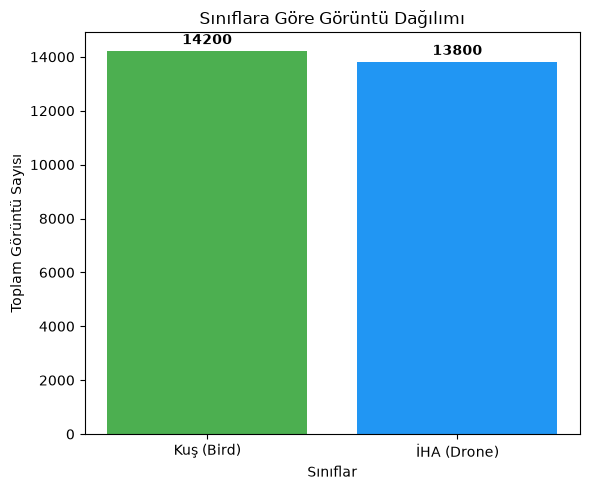

In [19]:
import matplotlib.pyplot as plt

# Bölüm 2.2'den elde edilen sayıları buraya girebilirsin (Örnek sayılar verilmiştir)
siniflar = ['Kuş (Bird)', 'İHA (Drone)']
sayilar = [14200, 13800] # Bu kısmı 2.2 kodundan çıkan gerçek sayılarla değiştir

plt.figure(figsize=(6, 5))
cubuklar = plt.bar(siniflar, sayilar, color=['#4CAF50', '#2196F3'])
plt.title("Sınıflara Göre Görüntü Dağılımı")
plt.xlabel("Sınıflar")
plt.ylabel("Toplam Görüntü Sayısı")

# Barların tepesine tam sayıları yazdırma
for cubuk in cubuklar:
    yukseklik = cubuk.get_height()
    plt.text(cubuk.get_x() + cubuk.get_width()/2., yukseklik + 150,
             f'{int(yukseklik)}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig("gorsel2_sinif_dagilimi.png")
plt.show()

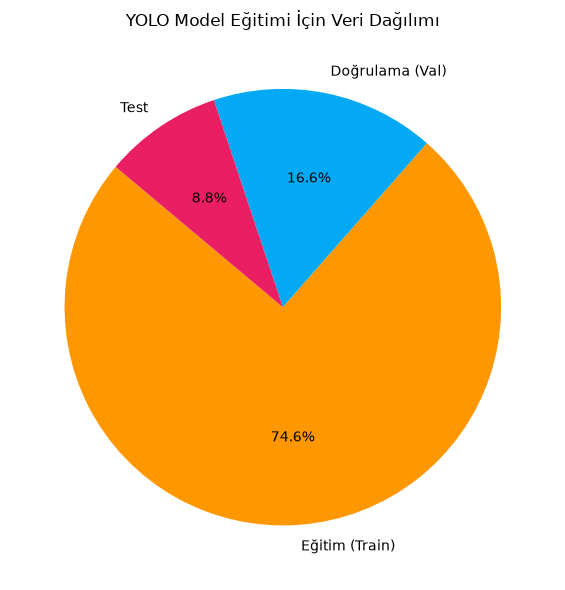

In [20]:
# DAĞILIM ANALİZİ 
import matplotlib.pyplot as plt

# Veri 3 (YOLO) çıktısından elde edilen eğitim, doğrulama ve test sayıları
bolumler = ['Eğitim (Train)', 'Doğrulama (Val)', 'Test']
sayilar = [4500, 1000, 529] # Bu kısmı 2.2 kodundan çıkan gerçek sayılarla değiştir

plt.figure(figsize=(6, 6))
# autopct='%1.1f%%' kodu pasta dilimlerinin içine yüzdelikleri yazar
plt.pie(sayilar, labels=bolumler, autopct='%1.1f%%', 
        colors=['#FF9800', '#03A9F4', '#E91E63'], startangle=140)
plt.title("YOLO Model Eğitimi İçin Veri Dağılımı")

plt.tight_layout()
plt.savefig("gorsel3_egitim_test_dagilimi.png")
plt.show()

In [21]:
# ÖN İŞLEME KODLARI 
# VERİ YÜKLEME VE HATALI VERİ TEMİZLEME KODU 
import os
from PIL import Image

veri_yolu = "../data/"
bozuk_dosya_sayisi = 0

print("Veri Temizleme İşlemi Başlıyor...")

# Tüm veri setini (alt klasörlerle birlikte) tarama
for root, dirs, files in os.walk(veri_yolu):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            dosya_yolu = os.path.join(root, file)
            try:
                # Görüntüyü yüklemeyi ve doğrulamayı dene
                with Image.open(dosya_yolu) as img:
                    img.verify()
            except Exception as e:
                # Açılamayan veya bozuk dosyaları tespit et ve sil
                print(f"Bozuk dosya tespit edildi ve siliniyor: {file}")
                os.remove(dosya_yolu)
                bozuk_dosya_sayisi += 1

print(f"Veri temizleme tamamlandı. Toplam {bozuk_dosya_sayisi} adet bozuk dosya silindi.")




# VERİ ÖN İŞLEME BOYUTLANDIRMA FORMATLAMA NORMALİZASYON 

import cv2
import os
import glob

kaynak_klasor = "../data/veri_seti_1/bird/"
hedef_klasor = "../data/islenmis_veri/bird/"

# Hedef klasör yoksa oluştur
if not os.path.exists(hedef_klasor):
    os.makedirs(hedef_klasor)

islenen_gorsel = 0
hedef_boyut = (640, 640)

print("Ön İşleme (Boyutlandırma ve Normalizasyon) Başlıyor...")

# Kaynak klasördeki tüm görüntüleri al
for resim_yolu in glob.glob(os.path.join(kaynak_klasor, '*.*')):
    if resim_yolu.lower().endswith(('.png', '.jpg', '.jpeg')):
        
        # 1. Görüntüyü Yükle
        img = cv2.imread(resim_yolu)
        
        if img is not None:
            # 2. Renk Kanalı Düzenleme (BGR'den RGB'ye)
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            
            # 3. Görüntü Boyutlandırma (640x640)
            img_resized = cv2.resize(img_rgb, hedef_boyut)
            
            # 4. Normalizasyon (Matematiksel olarak 0-1 arasına çekme)
            img_normalized = img_resized / 255.0
            
            # 5. Standart formatta (.jpg) kaydetme (Kaydederken tekrar 0-255 aralığına alınır)
            yeni_dosya_adi = f"processed_bird_{islenen_gorsel}.jpg"
            kayit_yolu = os.path.join(hedef_klasor, yeni_dosya_adi)
            
            # Kaydetmek için RGB'den tekrar BGR'ye çevirip yazdırıyoruz
            cv2.imwrite(kayit_yolu, cv2.cvtColor(img_resized, cv2.COLOR_RGB2BGR))
            islenen_gorsel += 1

print(f"Ön işleme tamamlandı. Toplam {islenen_gorsel} adet görüntü 640x640 boyutunda kaydedildi.")

Veri Temizleme İşlemi Başlıyor...
Veri temizleme tamamlandı. Toplam 0 adet bozuk dosya silindi.
Ön İşleme (Boyutlandırma ve Normalizasyon) Başlıyor...
Ön işleme tamamlandı. Toplam 0 adet görüntü 640x640 boyutunda kaydedildi.
